# Experiment 6: Fuzzy Logic and Constraint Satisfaction

**Aim:** Implement a simple fuzzy logic system and solve a constraint satisfaction problem using given rules and constraints.

## Theory

### Part A – Fuzzy Logic
In classical (crisp) logic a statement is either true (1) or false (0). Real-world concepts such as *"good attendance"* or *"high marks"* have no sharp boundary. **Fuzzy logic** (Lotfi Zadeh, 1965) lets a value belong to a set to a **degree between 0 and 1**, called the *membership degree*.

A fuzzy inference system (Mamdani type) has four steps:
1. **Fuzzification** – convert crisp inputs (e.g. attendance = 72 %) into membership degrees of linguistic terms (Low / Medium / High) using membership functions (triangular, trapezoidal, ...).
2. **Rule evaluation** – apply IF-THEN rules. `AND` = **min**, `OR` = **max**, `NOT` = 1 − x. The rule's firing strength clips its output fuzzy set.
3. **Aggregation** – combine the clipped output sets of all rules using **max**.
4. **Defuzzification** – convert the aggregated fuzzy set back to one crisp number, here with the **centroid** method: $x^* = \frac{\int x\,\mu(x)\,dx}{\int \mu(x)\,dx}$.

### Part B – Constraint Satisfaction Problem (CSP)
A CSP is defined by a triple **(X, D, C)**:
* **X** – set of variables (here: courses),
* **D** – domain of each variable (here: time slots),
* **C** – constraints restricting which value combinations are allowed.

A solution is a complete assignment that violates no constraint. The standard algorithm is **backtracking search**: assign variables one by one, check constraints, and undo (backtrack) on a conflict. Improvements used here: **MRV** (pick the variable with the fewest remaining values) and **forward checking** (remove values from neighbours' domains that become impossible).

## Exercise 1 – Fuzzy system for *Student Performance*

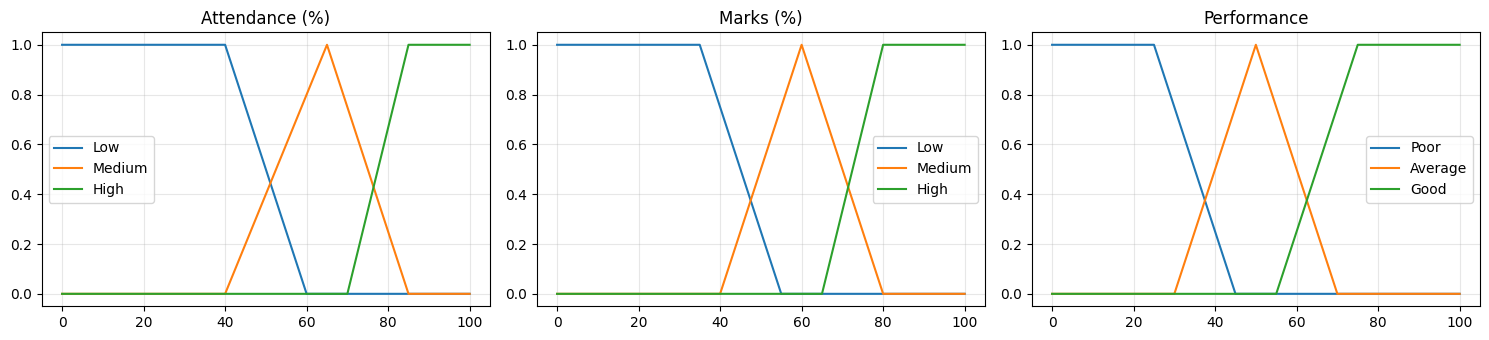

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- membership functions ----------
def trimf(x, a, b, c):
    x = np.asarray(x, dtype=float)
    left  = np.where(b != a, (x - a) / (b - a), 1.0)
    right = np.where(c != b, (c - x) / (c - b), 1.0)
    return np.clip(np.minimum(left, right), 0, 1)

def trapmf(x, a, b, c, d):
    x = np.asarray(x, dtype=float)
    left  = np.where(b != a, (x - a) / (b - a), 1.0)
    right = np.where(d != c, (d - x) / (d - c), 1.0)
    return np.clip(np.minimum(np.minimum(left, 1), right), 0, 1)

# ---------- universes & fuzzy sets ----------
universe = np.arange(0, 101, 1)

attendance_sets = {
    'Low':    lambda x: trapmf(x, -1, 0, 40, 60),
    'Medium': lambda x: trimf(x, 40, 65, 85),
    'High':   lambda x: trapmf(x, 70, 85, 100, 101),
}
marks_sets = {
    'Low':    lambda x: trapmf(x, -1, 0, 35, 55),
    'Medium': lambda x: trimf(x, 40, 60, 80),
    'High':   lambda x: trapmf(x, 65, 80, 100, 101),
}
performance_sets = {
    'Poor':    lambda x: trapmf(x, -1, 0, 25, 45),
    'Average': lambda x: trimf(x, 30, 50, 70),
    'Good':    lambda x: trapmf(x, 55, 75, 100, 101),
}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, (title, sets) in zip(ax, [('Attendance (%)', attendance_sets),
                                 ('Marks (%)', marks_sets),
                                 ('Performance', performance_sets)]):
    for name, f in sets.items():
        a.plot(universe, f(universe), label=name)
    a.set_title(title); a.set_ylim(-0.05, 1.05); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

Attendance=72, Marks=68
  Attendance degrees: {'Low': 0.0, 'Medium': 0.65, 'High': 0.13}
  Marks degrees     : {'Low': 0.0, 'Medium': 0.6, 'High': 0.2}
  Rules fired       : [('Medium', 'Medium', 'Average', 0.6), ('Medium', 'High', 'Good', 0.2), ('High', 'Medium', 'Good', 0.133), ('High', 'High', 'Good', 0.133)]
  Performance score = 59.55


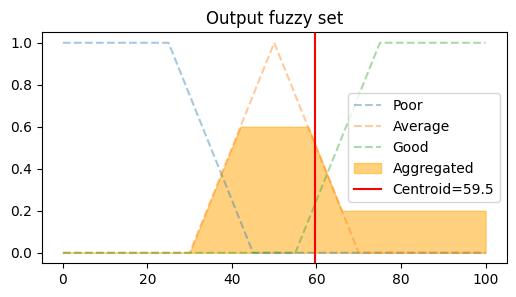

59.54935622317596

In [2]:
# ---------- rule base: (attendance term, marks term, performance term) ----------
RULES_V1 = [
    ('Low',    'Low',    'Poor'),
    ('Low',    'Medium', 'Poor'),
    ('Low',    'High',   'Average'),
    ('Medium', 'Low',    'Poor'),
    ('Medium', 'Medium', 'Average'),
    ('Medium', 'High',   'Good'),
    ('High',   'Low',    'Average'),
    ('High',   'Medium', 'Good'),
    ('High',   'High',   'Good'),
]

def fuzzy_performance(att, marks, rules, verbose=False, plot=False):
    # 1. Fuzzification
    att_deg   = {k: float(f(att))   for k, f in attendance_sets.items()}
    marks_deg = {k: float(f(marks)) for k, f in marks_sets.items()}

    # 2. Rule evaluation (AND = min) + 3. Aggregation (max)
    aggregated = np.zeros_like(universe, dtype=float)
    fired = []
    for a_t, m_t, p_t in rules:
        strength = min(att_deg[a_t], marks_deg[m_t])
        if strength > 0:
            clipped = np.minimum(strength, performance_sets[p_t](universe))
            aggregated = np.maximum(aggregated, clipped)
            fired.append((a_t, m_t, p_t, round(strength, 3)))

    # 4. Defuzzification (centroid)
    if aggregated.sum() == 0:
        return 0.0
    score = float((universe * aggregated).sum() / aggregated.sum())

    if verbose:
        print(f"Attendance={att}, Marks={marks}")
        print("  Attendance degrees:", {k: round(v, 2) for k, v in att_deg.items()})
        print("  Marks degrees     :", {k: round(v, 2) for k, v in marks_deg.items()})
        print("  Rules fired       :", fired)
        print(f"  Performance score = {score:.2f}")
    if plot:
        plt.figure(figsize=(6, 3))
        for n, f in performance_sets.items():
            plt.plot(universe, f(universe), '--', alpha=.4, label=n)
        plt.fill_between(universe, aggregated, alpha=.5, color='orange', label='Aggregated')
        plt.axvline(score, color='red', label=f'Centroid={score:.1f}')
        plt.legend(); plt.title('Output fuzzy set'); plt.show()
    return score

def label(score):
    return 'Poor' if score < 40 else 'Average' if score < 65 else 'Good'

fuzzy_performance(72, 68, RULES_V1, verbose=True, plot=True)

### Observation: how output changes with attendance and marks

In [3]:
import pandas as pd
tests = [(20,20),(30,80),(50,50),(60,60),(75,55),(72,68),(85,40),(90,90),(95,30),(100,100)]
rows = []
for att, mk in tests:
    s = fuzzy_performance(att, mk, RULES_V1)
    rows.append({'Attendance': att, 'Marks': mk, 'Score': round(s, 2), 'Category': label(s)})
df1 = pd.DataFrame(rows)
df1

,Attendance,Marks,Score,Category
0,20,20,17.72,Poor
1,30,80,50.00,Average
2,50,50,30.98,Poor
3,60,60,50.00,Average
4,75,55,64.39,Average
5,72,68,59.55,Average
6,85,40,50.00,Average
7,90,90,82.28,Good
8,95,30,50.00,Average
9,100,100,82.28,Good


**Observation (Exercise 1):** Performance rises smoothly as either input increases. Low attendance pulls the score down even when marks are high (e.g. 30, 80), and high attendance cannot fully rescue very low marks (85, 40). Because of overlapping membership functions there are no sudden jumps – unlike crisp `if/else` thresholds.

## Exercise 3 (part 1) – Change the fuzzy rules and compare

In [5]:
# Stricter rule base: marks matter more; 'Good' needs BOTH high attendance and high marks
RULES_V2 = [
    ('Low',    'Low',    'Poor'),
    ('Low',    'Medium', 'Poor'),
    ('Low',    'High',   'Poor'),      # changed: was Average
    ('Medium', 'Low',    'Poor'),
    ('Medium', 'Medium', 'Average'),
    ('Medium', 'High',   'Average'),   # changed: was Good
    ('High',   'Low',    'Poor'),      # changed: was Average
    ('High',   'Medium', 'Average'),   # changed: was Good
    ('High',   'High',   'Good'),
]
rows = []
for att, mk in tests:
    s1 = fuzzy_performance(att, mk, RULES_V1); s2 = fuzzy_performance(att, mk, RULES_V2)
    rows.append({'Attendance': att, 'Marks': mk,
                 'Score (V1)': round(s1, 1), 'Cat V1': label(s1),
                 'Score (V2 strict)': round(s2, 1), 'Cat V2': label(s2),
                 'Change': round(s2 - s1, 1)})
pd.DataFrame(rows)

,Attendance,Marks,Score (V1),Cat V1,Score (V2 strict),Cat V2,Change
0,20,20,17.7,Poor,17.7,Poor,0.0
1,30,80,50.0,Average,17.7,Poor,-32.3
2,50,50,31.0,Poor,31.0,Poor,0.0
3,60,60,50.0,Average,50.0,Average,0.0
4,75,55,64.4,Average,50.0,Average,-14.4
5,72,68,59.5,Average,57.0,Average,-2.6
6,85,40,50.0,Average,18.7,Poor,-31.3
7,90,90,82.3,Good,82.3,Good,0.0
8,95,30,50.0,Average,17.7,Poor,-32.3
9,100,100,82.3,Good,82.3,Good,0.0


**Observation (Exercise 3a):** With the stricter rules, students who are strong in only one input lose a lot: (30, 80) falls from 50 to 17.7 (Average → Poor), (85, 40) from 50 to 18.7, and (95, 30) from 50 to 17.7. Borderline cases such as (75, 55) and (72, 68) drop moderately, while students strong or weak in *both* inputs ((20,20), (90,90), (100,100)) are unchanged. This shows the rule base (not just the membership functions) defines the system's behaviour.

## Exercise 2 – Timetable problem as a CSP

**Variables:** courses · **Domains:** time slots · **Constraints:**
1. All courses use one room → no two courses in the same slot (*all-different*).
2. Math and Physics have the same teacher → already covered by (1) here, but kept explicit for clarity.
3. Math cannot be in `Wed-9`.
4. English cannot be at `Mon-9`.
5. CS must be scheduled **before** Physics.

In [6]:
import itertools
from copy import deepcopy

SLOTS = ['Mon-9', 'Mon-10', 'Tue-9', 'Tue-10', 'Wed-9']
order = {s: i for i, s in enumerate(SLOTS)}

def make_problem():
    variables = ['Math', 'Physics', 'CS', 'English', 'Chemistry']
    domains = {v: list(SLOTS) for v in variables}
    # unary constraints
    domains['Math'].remove('Wed-9')
    domains['English'].remove('Mon-9')
    # binary constraints: dict {(A,B): function(valA, valB) -> bool}
    constraints = {}
    def add(a, b, fn):
        constraints[(a, b)] = fn
        constraints[(b, a)] = lambda y, x, fn=fn: fn(x, y)
    for a, b in itertools.combinations(variables, 2):
        add(a, b, lambda x, y: x != y)                      # different slots
    add('CS', 'Physics', lambda cs, ph: order[cs] < order[ph])   # CS before Physics
    return variables, domains, constraints

def consistent(var, val, assignment, constraints):
    return all(constraints[(var, o)](val, ov)
               for o, ov in assignment.items() if (var, o) in constraints)

def backtrack(assignment, domains, variables, constraints, all_solutions=None, stats=None):
    if len(assignment) == len(variables):
        if all_solutions is not None:
            all_solutions.append(dict(assignment)); return None
        return dict(assignment)
    # MRV: variable with fewest remaining values
    var = min((v for v in variables if v not in assignment), key=lambda v: len(domains[v]))
    for val in list(domains[var]):
        stats['nodes'] += 1
        if consistent(var, val, assignment, constraints):
            assignment[var] = val
            # forward checking
            saved = deepcopy(domains); ok = True
            for other in variables:
                if other in assignment: continue
                domains[other] = [x for x in domains[other]
                                  if constraints[(other, var)](x, val)]
                if not domains[other]: ok = False; break
            if ok:
                res = backtrack(assignment, domains, variables, constraints, all_solutions, stats)
                if res is not None: return res
            domains.clear(); domains.update(saved)
            del assignment[var]
    return None

def solve(variables, domains, constraints, find_all=False):
    stats = {'nodes': 0}
    if find_all:
        sols = []; backtrack({}, deepcopy(domains), variables, constraints, sols, stats)
        return sols, stats
    return backtrack({}, deepcopy(domains), variables, constraints, None, stats), stats

def show(sol):
    if not sol: print('No solution exists.'); return
    tt = pd.DataFrame({'Course': list(sol), 'Slot': list(sol.values())})
    tt['o'] = tt['Slot'].map(order)
    print(tt.sort_values('o')[['Slot', 'Course']].to_string(index=False))

variables, domains, constraints = make_problem()
solution, stats = solve(variables, domains, constraints)
print("Timetable found (nodes explored:", stats['nodes'], ")\n")
show(solution)

Timetable found (nodes explored: 6 )

  Slot    Course
 Mon-9      Math
Mon-10        CS
 Tue-9   Physics
Tue-10   English
 Wed-9 Chemistry


In [7]:
# Verify no constraint is violated & count all solutions
def verify(sol, constraints):
    return all(constraints[(a, b)](sol[a], sol[b]) for (a, b) in constraints)

all_sols, st = solve(variables, domains, constraints, find_all=True)
print("Valid (no violation):", verify(solution, constraints))
print("Total number of valid timetables:", len(all_sols))

Valid (no violation): True
Total number of valid timetables: 39


**Observation (Exercise 2):** The solver returns a timetable where every course has its own slot, Math is not on Wed-9, English is not on Mon-9, and CS comes before Physics. `verify()` confirms no constraint is violated.

## Exercise 3 (part 2) – Change the constraints and re-run

In [8]:
# New constraint set:
#  (a) Chemistry must be on Tuesday (Tue-9 or Tue-10)
#  (b) Math must be immediately before English (consecutive slots)
variables2, domains2, constraints2 = make_problem()
domains2['Chemistry'] = [s for s in domains2['Chemistry'] if s.startswith('Tue')]
def add2(a, b, fn):
    constraints2[(a, b)] = lambda x, y, old=constraints2[(a, b)], fn=fn: old(x, y) and fn(x, y)
    constraints2[(b, a)] = lambda y, x, old=constraints2[(b, a)], fn=fn: old(y, x) and fn(x, y)
add2('Math', 'English', lambda m, e: order[e] - order[m] == 1)

sol2, st2 = solve(variables2, domains2, constraints2)
print("Modified timetable:\n"); show(sol2)
all2, _ = solve(variables2, domains2, constraints2, find_all=True)
print("\nNumber of valid timetables: before =", len(all_sols), "| after =", len(all2))

# Tight example: Physics fixed at Mon-10 (forces CS into Mon-9)
variables3, domains3, constraints3 = make_problem()
domains3['Physics'] = ['Mon-10']
sol3, _ = solve(variables3, domains3, constraints3)
print("\nTight case (Physics fixed at Mon-10, CS must precede it):")
show(sol3)

Modified timetable:

  Slot    Course
 Mon-9      Math
Mon-10   English
 Tue-9 Chemistry
Tue-10        CS
 Wed-9   Physics

Number of valid timetables: before = 39 | after = 4

Tight case (Physics fixed at Mon-10, CS must precede it):
  Slot    Course
 Mon-9        CS
Mon-10   Physics
 Tue-9      Math
Tue-10   English
 Wed-9 Chemistry


**Observation (Exercise 3b):** Adding constraints *shrinks* the solution space (number of valid timetables drops) and changes the generated timetable. In the second test, Physics is fixed at Mon-10, which forces CS into Mon-9; a solution still exists, but only because that one slot was free. Had we also blocked CS from Mon-9, the problem would be over-constrained and have **no solution** – the solver would report this after exhausting all options.

## Conclusion
* A fuzzy inference system (fuzzification → rules → aggregation → defuzzification) handles imprecise concepts and gives smooth outputs; changing the **rules** directly changes the decision behaviour.
* A CSP with backtracking, MRV and forward checking finds schedules that satisfy all constraints; changing the **constraints** alters or removes solutions.